# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 09: Synthetic Iris Generator

### Objective

This notebook trains the **generator**: a conditional **diffusion model** that draws a normalized iris strip for a given identity under a given appearance.

```text
generator( identity embedding of person P , appearance code a )  ->  an iris strip of P that looks like "a"
```

The identity embedding and the appearance code come from the latent model of Notebook 08. In Notebook 10 the identity embedding of a training person is kept fixed while the appearance code is varied, which turns the few real images of that person into many identity-preserving synthetic ones.

The notebook must:

1. Train a diffusion model on the real normalized iris images of the few-shot **training** split only.
2. Condition it on the identity embedding (who) and the appearance code (how the photo looks).
3. Measure whether the generated images keep the requested identity, follow the requested appearance, are varied, and are not copies of the real images.
4. Save the **generator model** (one per shot count) for Notebook 10.

### Important boundary of this notebook

This notebook performs **generator training only**.

It does **not** produce the synthetic dataset (Notebook 10), verify synthetic identities with a recognizer (Notebook 11), or train any recognizer. Only the real `train / support` images update any weights; validation and test identities are used for model selection and reporting exactly as in Notebooks 06 to 08.

## 1. Research rationale

### 1.1 Why a diffusion model

The project plan allows a diffusion model or StyleGAN3, and the proposal recommends diffusion: training is stable and it covers the data distribution better (less mode collapse), which matters when the generator must produce *varied* samples of one person. StyleGAN3 needs NVIDIA's own CUDA code and a separate repository, so it is not included. The iris strips are small (64 x 512), so the diffusion runs directly on pixels and no separate latent-diffusion autoencoder is needed.

### 1.2 What the generator is conditioned on

| Condition | Source | Meaning |
|---|---|---|
| **Identity embedding** | Notebook 08: the normalised mean of `z_id` over the person's `K` support images | Who the iris belongs to |
| **Appearance code** | Notebook 08: `z_app` of the image (standardised) | Illumination, rotation, dilation, blur, noise |

This is the `I_syn = G(z_id, z_app, ...)` form of the proposal. Both parts are concatenated and injected into every block of the network.

### 1.3 Diffusion in one paragraph

Noise is gradually added to a real image until nothing is left; the network learns to predict the noise that was added. To generate, it starts from pure noise and removes the predicted noise step by step. Here sampling uses **DDIM** (50 steps by default) with **classifier-free guidance**: during training the condition is dropped 10% of the time (replaced by a learned "no condition" vector), so at sampling time the prediction can be pushed *towards* the condition with `eps = eps_uncond + w * (eps_cond - eps_uncond)`. A larger `w` follows the identity more strictly and is less varied.

### 1.4 Training views: why appearance-transformed images are used

With 1 to 5 images per person the generator would see only one appearance per person, so it could never learn how the appearance code changes *that person's* iris. Each training image is therefore, with probability `AUGMENT_PROB`, replaced by an **appearance-transformed view** of itself (the same transform as Notebook 08: rotation, radial stretch, brightness/contrast, blur, noise), and the appearance code is **re-encoded from the view actually shown**. The identity condition always stays the person's embedding.

> **Important for the final comparison.** This is the same family of transformations as the *traditional augmentation* baseline of Notebook 07. Notebook 16 should therefore compare the generator **against** that baseline, so that any gain of the synthetic data over plain augmentation is demonstrated, not assumed.

### 1.4b EMA weights

A running exponential average of the weights (EMA) is kept and used for validation and sampling; it is the usual way to get stable, cleaner diffusion samples.

### 1.5 How the generator is judged

All diagnostics use the **frozen Notebook 08 encoder** as the judge (a recognizer-based check follows in Notebook 11).

| Diagnostic | Meaning | Good looks like |
|---|---|---|
| **Identity consistency** (`gen_rank1`) | Re-encode generated images: is the nearest identity embedding the requested one? | Far above chance, and close to `real_rank1` (the same score for real images); `id_ratio` near 1 |
| **Appearance fidelity** | Is the re-encoded appearance code closer to the requested code than to another one? | Clearly above 0.5 |
| **Diversity ratio** | Pixel difference between generated images of one person, relative to real images of that person | Not far below 1 (much below 1 = mode collapse) |
| **Copy ratio** | Distance from a generated image to the nearest real support image of the same person, relative to real-vs-real distance | Not close to 0 (close to 0 = the model copies its training images) |
| **Image statistics** | Mean, spread, and sharpness of generated vs. real images | Similar to real |
| **Validation loss** | Denoising loss on unseen people with fixed noise | Used only to pick the best checkpoint |

Diagnostics are computed for **training people** (the generator should do well), **validation people** and **test people** (identities it never trained on; reported for information, not required).

### 1.6 Protocol and leakage rules

Identical to Notebooks 07 and 08: trained on `train / support` of `TRAIN_DATASETS` only; `val` picks the best checkpoint; `test` is evaluated once at the end. Before every run the notebook asserts that no training image, class, or person appears in any evaluation set.

### 1.7 Things to keep in mind

- **The default settings are untested starting values.** Diffusion needs many training steps; the log prints the speed so you can judge the cost, and `TRAIN_STEPS` / `UNET_BASE` are the main knobs.
- **Check the pictures** (section 17) as well as the numbers: statistics cannot tell a plausible iris from a noisy blob.
- **Run `QUICK_TEST = True` first.**
- **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import hashlib
import json
import math
import random
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision.transforms import functional as tv_F
except ImportError as error:
    raise ImportError(
        "Notebook 09 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished run is skipped on re-run only if its stored fingerprint matches, so changing a hyperparameter can never silently reuse stale results.

- `QUICK_TEST = True` shrinks everything (a tiny network, a few hundred steps, a handful of identities) to check the whole pipeline before a long run. It reads **Notebook 08's quick-test outputs** and writes to a separate folder.
- `LATENT_*` choose which Notebook 08 latent model supplies the codes (it must exist for every shot you run).
- `UNET_BASE` is the width of the network (cost grows roughly with its square). `TRAIN_STEPS` is the number of optimizer steps **per shot**.
- `GUIDANCE_SCALE` is the classifier-free guidance weight used for sampling.
- `EVAL_EVERY_STEPS` must be a multiple of `LOG_EVERY_STEPS`.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = tiny smoke test, written to a separate folder

# ---- what to run ----
SHOTS_TO_RUN = [1, 2, 3, 5]
SEEDS = [42]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]

# ---- the Notebook 08 latent model that supplies the identity / appearance codes ----
LATENT_ENCODER = "cnn"
LATENT_MODE = "vae"
LATENT_SEED = 42
LATENT_FROM_QUICKTEST = QUICK_TEST      # QUICK_TEST reads Notebook 08's quick-test outputs

INPUT_HW = (64, 512)        # normalized iris strips from Notebook 03

# ---- U-Net ----
UNET_BASE = 32              # channel width (must be a multiple of 8); 64 is stronger and about 4x slower
UNET_MULTS = (1, 2, 4, 4)   # channel multipliers per resolution level
UNET_RES_BLOCKS = 2
UNET_ATTN_LEVELS = (2, 3)   # levels that use self-attention
UNET_HEADS = 4

# ---- diffusion ----
DIFFUSION_STEPS = 1000
NOISE_SCHEDULE = "cosine"   # "cosine" or "linear"
P_UNCOND = 0.1              # probability of dropping the condition during training (classifier-free guidance)

# ---- training (steps, not epochs) ----
TRAIN_STEPS = 8000
BATCH_SIZE = 32
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.0
WARMUP_STEPS = 500
MIN_LR_FRACTION = 0.1       # the learning rate decays (cosine) to this fraction of LEARNING_RATE
GRAD_CLIP = 1.0
EMA_DECAY = 0.999
AUGMENT_PROB = 0.5          # chance that a training image is shown as an appearance-transformed view
MIXED_PRECISION = True      # used only on CUDA
LOG_EVERY_STEPS = 200

# ---- model selection (validation identities only) ----
EVAL_EVERY_STEPS = 1000
EARLY_STOP_PATIENCE = 4     # evaluations without improvement before stopping
VAL_MAX_IMAGES = 1000

# ---- sampling and generation diagnostics ----
SAMPLE_STEPS = 50           # DDIM steps
DDIM_ETA = 0.0              # 0 = deterministic DDIM, 1 = DDPM-like
GUIDANCE_SCALE = 2.0        # classifier-free guidance weight (1 = no guidance)
SAMPLE_BATCH_SIZE = 32
EVAL_IDENTITIES = 100       # identities per evaluation set used for the diagnostics
SAMPLES_PER_IDENTITY = 2
APP_BANK_VIEWS = 3          # transformed views per training image stored in the appearance-code bank

# ---- appearance transform (identical to Notebook 08; do not change) ----
APP_MAX_SHIFT = 32
APP_RADIAL_STRENGTH = 0.25
APP_BRIGHTNESS = 0.2
APP_CONTRAST = 0.25
APP_BLUR_PROB = 0.4
APP_NOISE_PROB = 0.4
APP_NOISE_STD = 0.05

# ---- evaluation sets ----
EVAL_SEED = 2024
CROSS_DATASET_USE_ALL_SPLITS = True
EVALUATE_TRAIN_CLOSED_SET = True

# ---- bookkeeping ----
MAX_TRAIN_CLASSES = None
RESUME = True
SAVE_CHECKPOINTS = True

if QUICK_TEST:
    SHOTS_TO_RUN = [1, 3]
    UNET_BASE = 16
    TRAIN_STEPS = 200
    BATCH_SIZE = 16
    WARMUP_STEPS = 20
    LOG_EVERY_STEPS = 50
    EVAL_EVERY_STEPS = 100
    VAL_MAX_IMAGES = 100
    SAMPLE_STEPS = 10
    EVAL_IDENTITIES = 8
    APP_BANK_VIEWS = 1
    MAX_TRAIN_CLASSES = 60
    print("QUICK_TEST is ON: tiny experiment, separate output folder, reads Notebook 08's quick-test outputs.")

# ---- sanity checks on the configuration itself ----
assert tuple(INPUT_HW) == (64, 512), "This notebook assumes 64 x 512 iris strips"
assert UNET_BASE % 8 == 0 and UNET_BASE >= 16, "UNET_BASE must be a multiple of 8 (at least 16)"
assert all((UNET_BASE * m) % UNET_HEADS == 0 for m in UNET_MULTS), "UNET_HEADS must divide every channel width"
assert all(0 <= level < len(UNET_MULTS) for level in UNET_ATTN_LEVELS), "UNET_ATTN_LEVELS out of range"
assert NOISE_SCHEDULE in {"cosine", "linear"}, "NOISE_SCHEDULE must be 'cosine' or 'linear'"
assert EVAL_EVERY_STEPS % LOG_EVERY_STEPS == 0, "EVAL_EVERY_STEPS must be a multiple of LOG_EVERY_STEPS"
assert 0.0 <= P_UNCOND < 1.0 and 0.0 <= AUGMENT_PROB <= 1.0
assert len(SEEDS) >= 1 and len(SHOTS_TO_RUN) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Shots:", SHOTS_TO_RUN, "| seeds:", SEEDS, "| device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no CUDA GPU found. Diffusion training is very slow on CPU; use QUICK_TEST = True.")

Shots: [1, 2, 3, 5] | seeds: [42] | device: cuda | mixed precision: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
# ============================================================
# 4b. Output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
latent_suffix = "_quicktest" if LATENT_FROM_QUICKTEST else ""

RESULTS_DIR = PROJECT_ROOT / "results" / f"diffusion_generator{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"diffusion_generator{suffix}"

NOTEBOOK08_RESULTS_DIR = PROJECT_ROOT / "results" / f"identity_latent_space{latent_suffix}"
NOTEBOOK08_CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"identity_latent_space{latent_suffix}"

for directory in [RESULTS_DIR, RUNS_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 09 results:", RESULTS_DIR)
print("Generator checkpoints:", CHECKPOINT_DIR)
print("Reading Notebook 08 from:", NOTEBOOK08_RESULTS_DIR)

Notebook 09 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator
Generator checkpoints: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\diffusion_generator
Reading Notebook 08 from: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space


## 5. Utility functions

Images are read once, cached as `uint8`, and batched manually (no `DataLoader` worker processes), which avoids the multiprocessing problems Jupyter has on Windows. `make_generator` gives a random generator with a fixed seed so evaluation noise is identical for every model.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_generator(seed):
    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(int(seed))
    return generator


def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def latent_run_id(shot):
    return f"{LATENT_ENCODER}_{LATENT_MODE}__{shot}shot__seed{LATENT_SEED}"


def latent_paths(shot):
    '''(Notebook 08 checkpoint, Notebook 08 identity-embedding file) for this shot.'''
    run_id = latent_run_id(shot)
    return (NOTEBOOK08_CHECKPOINT_DIR / f"{run_id}.pt",
            NOTEBOOK08_RESULTS_DIR / "identity_embeddings" / f"{run_id}.npz")

## 6. Load the few-shot dataset and check the Notebook 08 outputs

`fewshot_manifest_long.csv` (Notebook 06) is the only source of images. For every shot you run, the matching Notebook 08 latent model and identity-embedding file must exist; the notebook checks this **before** any training starts.

In [6]:
# ============================================================
# 6. Load the few-shot dataset
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {
    "shot", "image_id", "dataset", "class_id", "subject_key",
    "split", "role", "relative_path", "source_path",
}

missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
available_shots = sorted(long_manifest["shot"].unique())

for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, (
        f"TRAIN_DATASETS contains '{dataset_name}', which is not in the manifest {available_datasets}"
    )

shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot was requested but does not exist in the manifest; skipping it.")

if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the manifest.")

# Notebook 08 must have produced the latent model and identity embeddings for every shot
missing_latent = [str(p) for shot in shots_to_run for p in latent_paths(shot) if not p.exists()]
if missing_latent:
    raise FileNotFoundError(
        "Notebook 08 outputs are missing:\n  " + "\n  ".join(missing_latent)
        + "\nRun 08_Identity_Latent_Space.ipynb first (same shots; same LATENT_ENCODER / LATENT_MODE / LATENT_SEED; "
          "QUICK_TEST here reads Notebook 08's quick-test outputs)."
    )

latent_signature = {
    int(shot): [[p.stat().st_size, int(p.stat().st_mtime)] for p in latent_paths(shot)] for shot in shots_to_run
}

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)

train_overview = (
    long_manifest[
        (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ]
    .groupby("shot")
    .agg(train_classes=("class_id", "nunique"), train_images=("image_id", "count"))
    .reset_index()
)

display(train_overview)

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS,
    "latent": [LATENT_ENCODER, LATENT_MODE, LATENT_SEED, LATENT_FROM_QUICKTEST],
    "latent_signature": latent_signature,
    "input_hw": list(INPUT_HW),
    "unet": [UNET_BASE, list(UNET_MULTS), UNET_RES_BLOCKS, list(UNET_ATTN_LEVELS), UNET_HEADS],
    "diffusion": [DIFFUSION_STEPS, NOISE_SCHEDULE, P_UNCOND],
    "train": [TRAIN_STEPS, BATCH_SIZE, LEARNING_RATE, WEIGHT_DECAY, WARMUP_STEPS, MIN_LR_FRACTION,
              GRAD_CLIP, EMA_DECAY, AUGMENT_PROB],
    "selection": [EVAL_EVERY_STEPS, EARLY_STOP_PATIENCE, VAL_MAX_IMAGES],
    "sampling": [SAMPLE_STEPS, DDIM_ETA, GUIDANCE_SCALE, EVAL_IDENTITIES, SAMPLES_PER_IDENTITY, APP_BANK_VIEWS],
    "transform": [APP_MAX_SHIFT, APP_RADIAL_STRENGTH, APP_BRIGHTNESS, APP_CONTRAST, APP_BLUR_PROB,
                  APP_NOISE_PROB, APP_NOISE_STD],
    "eval": [EVAL_SEED, CROSS_DATASET_USE_ALL_SPLITS, EVALUATE_TRAIN_CLOSED_SET],
    "max_train_classes": MAX_TRAIN_CLASSES,
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 2, 3, 5]


,shot,train_classes,train_images
0,1,1390,1390
1,2,1384,2768
2,3,1369,4107
3,5,1294,6470


Configuration fingerprint: dd6fde437034


## 7. Training set and evaluation sets

Exactly as in Notebooks 07 and 08.

**Training set** for shot `K`: `split == train`, `role == support`, `dataset in TRAIN_DATASETS`. Nothing else.

**Evaluation sets** (gallery = `support` rows, probes = `query` rows of the same classes):

| Name | Data | Use here |
|---|---|---|
| `<train dataset>/val` | unseen people | Validation loss (picks the best checkpoint) and diagnostics |
| `<train dataset>/test` | unseen people | Diagnostics, evaluated once per run |
| `<train dataset>/train_closed` | training people | Diagnostics (how well the generator does on the identities it trained on) |
| `<other dataset>/cross_dataset` | a dataset never seen in training | Included in the leakage assertion only |

Before every training run the notebook asserts that no training image, class, or person appears in a validation, test, or cross-dataset set.

In [7]:
# ============================================================
# 7. Training set and evaluation sets
# ============================================================

def build_eval_set_specs():
    specs = []

    for dataset_name in available_datasets:
        if dataset_name in TRAIN_DATASETS:
            specs.append({"name": f"{dataset_name}/val", "dataset": dataset_name,
                          "splits": ["val"], "kind": "selection"})
            specs.append({"name": f"{dataset_name}/test", "dataset": dataset_name,
                          "splits": ["test"], "kind": "within_dataset_test"})
            if EVALUATE_TRAIN_CLOSED_SET:
                specs.append({"name": f"{dataset_name}/train_closed", "dataset": dataset_name,
                              "splits": ["train"], "kind": "train_closed_set_diagnostic"})
        else:
            splits = ["train", "val", "test"] if CROSS_DATASET_USE_ALL_SPLITS else ["test"]
            specs.append({"name": f"{dataset_name}/cross_dataset", "dataset": dataset_name,
                          "splits": splits, "kind": "cross_dataset"})

    return specs


EVAL_SET_SPECS = build_eval_set_specs()


def get_training_set(shot):
    train_df = long_manifest[
        (long_manifest["shot"] == shot)
        & (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ].copy()

    if MAX_TRAIN_CLASSES is not None:
        # Deterministic subset that does not depend on the shot or the seed.
        ordered = sorted(train_df["class_id"].unique(), key=lambda c: (zlib.crc32(c.encode("utf-8")), c))
        keep = set(ordered[:MAX_TRAIN_CLASSES])
        train_df = train_df[train_df["class_id"].isin(keep)].copy()

    sort_columns = ["class_id", "shuffle_rank"] if "shuffle_rank" in train_df.columns else ["class_id", "image_id"]
    return train_df.sort_values(sort_columns).reset_index(drop=True)


def get_eval_pool_defs(shot):
    '''Gallery (support) and probe (query) rows for every evaluation set at this shot.'''
    pool_defs = {}

    for spec in EVAL_SET_SPECS:
        rows = long_manifest[
            (long_manifest["shot"] == shot)
            & (long_manifest["dataset"] == spec["dataset"])
            & (long_manifest["split"].isin(spec["splits"]))
        ]
        support = rows[rows["role"] == "support"]
        query = rows[rows["role"] == "query"]

        if len(support) == 0 or len(query) == 0:
            continue

        pool_defs[spec["name"]] = {"spec": spec, "support_df": support, "query_df": query}

    return pool_defs


def materialize_pool(pool_def):
    support, query = pool_def["support_df"], pool_def["query_df"]
    return {
        "support_images": load_image_tensor(support),
        "support_labels": support["class_id"].to_numpy(),
        "query_images": load_image_tensor(query),
        "query_labels": query["class_id"].to_numpy(),
    }


def assert_no_leakage(train_df, pool_defs):
    '''Raise if any training image, class, or person is also used for evaluation.'''
    train_images = set(train_df["image_id"])
    train_classes = set(train_df["class_id"])
    train_subjects = set(train_df["subject_key"])

    for name, pool_def in pool_defs.items():
        kind = pool_def["spec"]["kind"]
        query_images = set(pool_def["query_df"]["image_id"])

        # Probes must never be training images, for every kind of evaluation set.
        assert not (train_images & query_images), f"{name}: a probe image was used for training"

        if kind == "train_closed_set_diagnostic":
            continue  # same people on purpose; only the image-level rule above applies

        eval_df = pd.concat([pool_def["support_df"], pool_def["query_df"]])
        assert not (train_images & set(eval_df["image_id"])), f"{name}: shares images with the training set"
        assert not (train_classes & set(eval_df["class_id"])), f"{name}: shares classes with the training set"
        assert not (train_subjects & set(eval_df["subject_key"])), f"{name}: shares people with the training set"

    return True


print("Evaluation sets:")
display(pd.DataFrame(EVAL_SET_SPECS))

Evaluation sets:


,name,dataset,splits,kind
0,CASIA-Iris-Thousand/val,CASIA-Iris-Thousand,[val],selection
1,CASIA-Iris-Thousand/test,CASIA-Iris-Thousand,[test],within_dataset_test
2,CASIA-Iris-Thousand/train_closed,CASIA-Iris-Thousand,[train],train_closed_set_diagnostic
3,IITD/cross_dataset,IITD,"[train, val, test]",cross_dataset


## 8. The Notebook 08 latent model (frozen) and the appearance transform

The classes below are **copied unchanged from Notebook 08** so that its checkpoint can be loaded here. The latent model is only used as a **frozen tool**:

- during training it encodes the (possibly transformed) training image into its appearance code;
- during evaluation it acts as the judge of identity and appearance in the generated images.

Its weights are never updated in this notebook.

In [8]:
# ============================================================
# 8. Notebook 08 latent model (copied) and appearance transform
# ============================================================

class ConvEncoder(nn.Module):
    def __init__(self, c):
        super().__init__()
        channels = [1, c, 2 * c, 4 * c, 8 * c, 8 * c]
        layers = []
        for i in range(5):                       # 64 x 512 -> 2 x 16
            layers += [nn.Conv2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.LeakyReLU(0.2, inplace=True)]
        self.net = nn.Sequential(*layers)
        self.out_dim = 8 * c * 2 * 16

    def forward(self, x):
        return self.net(x).flatten(1)


class ViTEncoder(nn.Module):
    def __init__(self, dim, depth, heads, patch):
        super().__init__()
        patch = tuple(patch)
        self.patch_embed = nn.Conv2d(1, dim, kernel_size=patch, stride=patch)
        n_tokens = (INPUT_HW[0] // patch[0]) * (INPUT_HW[1] // patch[1])
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, n_tokens + 1, dim))
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=2 * dim, dropout=0.0,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth)
        self.norm = nn.LayerNorm(dim)
        self.out_dim = dim

    def forward(self, x):
        tokens = self.patch_embed(x).flatten(2).transpose(1, 2)
        tokens = torch.cat([self.cls.expand(tokens.size(0), -1, -1), tokens], dim=1) + self.pos
        return self.norm(self.blocks(tokens)[:, 0])


class ConvDecoder(nn.Module):
    def __init__(self, latent_dim, c):
        super().__init__()
        self.base = 8 * c
        self.fc = nn.Linear(latent_dim, self.base * 2 * 16)
        channels = [8 * c, 8 * c, 4 * c, 2 * c, c]
        layers = []
        for i in range(4):                       # 2 x 16 -> 32 x 256
            layers += [nn.ConvTranspose2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.ReLU(inplace=True)]
        layers += [nn.ConvTranspose2d(c, 1, 4, 2, 1)]   # -> 64 x 512
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        h = F.relu(self.fc(z)).view(z.size(0), self.base, 2, 16)
        return torch.sigmoid(self.net(h))


class LatentModel(nn.Module):
    '''Encoder -> (z_id, z_app) -> decoder. mode "vae" samples the codes, "ae" uses the means.'''

    def __init__(self, arch):
        super().__init__()
        self.arch = dict(arch)
        self.mode = arch["mode"]

        if arch["encoder"] == "cnn":
            self.encoder = ConvEncoder(arch["base_channels"])
        else:
            self.encoder = ViTEncoder(arch["vit_dim"], arch["vit_depth"], arch["vit_heads"], arch["vit_patch"])

        features = self.encoder.out_dim
        self.fc_mu_id = nn.Linear(features, arch["id_dim"])
        self.fc_lv_id = nn.Linear(features, arch["id_dim"])
        self.fc_mu_app = nn.Linear(features, arch["app_dim"])
        self.fc_lv_app = nn.Linear(features, arch["app_dim"])
        self.decoder = ConvDecoder(arch["id_dim"] + arch["app_dim"], arch["base_channels"])

    def encode(self, x):
        '''x: float [B, 1, H, W] in [0, 1] -> mu_id, logvar_id, mu_app, logvar_app.'''
        h = self.encoder((x - 0.5) / 0.5)
        return (self.fc_mu_id(h), self.fc_lv_id(h).clamp(-10.0, 5.0),
                self.fc_mu_app(h), self.fc_lv_app(h).clamp(-10.0, 5.0))

    def sample(self, mu, logvar):
        if self.mode == "vae" and self.training:
            return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return mu

    def decode(self, z_id, z_app):
        return self.decoder(torch.cat([z_id, z_app], dim=1))


def load_latent_model(path):
    '''Rebuild a trained Notebook 08 model from its checkpoint.'''
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location="cpu")

    model = LatentModel(checkpoint["arch"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval(), checkpoint


def appearance_transform(x, gen=None, strength=1.0):
    '''x: float [B, 1, H, W] in [0, 1] on DEVICE. Returns a new view of the SAME iris.'''
    if strength == 0:
        return x

    batch, _, height, width = x.shape
    device = x.device

    def uniform(*shape):
        return torch.rand(*shape, device=device, generator=gen)

    # 1. rotation: circular shift along the angle axis
    shifts = torch.floor((uniform(batch) * 2 - 1) * APP_MAX_SHIFT * strength + 0.5).long()
    index = (torch.arange(width, device=device).unsqueeze(0) + shifts.unsqueeze(1)) % width
    x = torch.gather(x, 3, index.view(batch, 1, 1, width).expand(batch, 1, height, width))

    # 2. pupil dilation: radial stretch with fixed end points (gamma = 1 is an exact identity)
    gamma = torch.exp((uniform(batch) * 2 - 1) * APP_RADIAL_STRENGTH * strength).double()
    rows = torch.arange(height, device=device, dtype=torch.float64) / (height - 1)
    source = (rows.unsqueeze(0) ** gamma.unsqueeze(1)) * (height - 1)
    low = source.floor().clamp(0, height - 1)
    high = (low + 1).clamp(max=height - 1)
    weight = (source - low).clamp(0, 1).float().view(batch, 1, height, 1)
    low_index = low.long().view(batch, 1, height, 1).expand(batch, 1, height, width)
    high_index = high.long().view(batch, 1, height, 1).expand(batch, 1, height, width)
    x = torch.gather(x, 2, low_index) * (1 - weight) + torch.gather(x, 2, high_index) * weight

    # 3. illumination: brightness and contrast
    brightness = (uniform(batch, 1, 1, 1) * 2 - 1) * APP_BRIGHTNESS * strength
    contrast = 1 + (uniform(batch, 1, 1, 1) * 2 - 1) * APP_CONTRAST * strength
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean + brightness

    # 4. focus: blur on a random subset
    blurred = tv_F.gaussian_blur(x, kernel_size=[5, 5], sigma=[1.0, 1.0])
    x = torch.where(uniform(batch, 1, 1, 1) < APP_BLUR_PROB, blurred, x)

    # 5. sensor noise on a random subset
    noisy = (uniform(batch, 1, 1, 1) < APP_NOISE_PROB).float()
    x = x + noisy * torch.randn(x.shape, device=device, generator=gen) * APP_NOISE_STD * strength

    return x.clamp(0.0, 1.0)


def load_latent_assets(shot):
    '''Frozen Notebook 08 model and the identity embedding of every class, for this shot.'''
    run_id = latent_run_id(shot)
    checkpoint_path, embedding_path = latent_paths(shot)

    latent, checkpoint = load_latent_model(checkpoint_path)
    for parameter in latent.parameters():
        parameter.requires_grad_(False)

    embeddings = np.load(embedding_path, allow_pickle=False)
    table = dict(zip(embeddings["class_id"].tolist(), embeddings["embedding"]))

    return {"latent": latent, "table": table, "run_id": run_id,
            "id_dim": int(checkpoint["arch"]["id_dim"]), "app_dim": int(checkpoint["arch"]["app_dim"])}


print("Notebook 08 model classes and appearance transform defined.")

Notebook 08 model classes and appearance transform defined.


## 9. The diffusion model

```text
noisy strip x_t [1 x 64 x 512] -> pixel-unshuffle (2x2) -> [4 x 32 x 256]
   -> U-Net with 4 resolution levels, residual blocks and self-attention
      every block receives:  time-step embedding + condition embedding (scale and shift)
   -> pixel-shuffle -> predicted noise [1 x 64 x 512]
```

- The 2x2 **pixel-unshuffle** halves the working resolution, which cuts the cost of every convolution to about a quarter without changing the image size that is generated.
- The **condition** (identity embedding + standardised appearance code) is mapped by a small MLP to the same size as the time embedding and added to it, so every block is modulated by it.
- A learned **null condition** replaces the real condition when it is dropped during training; sampling with guidance uses both.
- The final layer starts at zero, so the untrained network predicts zero noise.
- `Diffusion` holds the noise schedule, `sample_images` runs DDIM sampling with classifier-free guidance, and `EMA` keeps the averaged weights used for sampling.

In [9]:
# ============================================================
# 9. U-Net, diffusion process, EMA, and sampling
# ============================================================

def timestep_embedding(t, dim):
    half = dim // 2
    frequencies = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    arguments = t.float().unsqueeze(1) * frequencies.unsqueeze(0)
    return torch.cat([torch.sin(arguments), torch.cos(arguments)], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, emb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.emb = nn.Linear(emb_dim, 2 * out_channels)          # per-channel scale and shift
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)
        self.skip = nn.Identity() if in_channels == out_channels else nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb(F.silu(emb)).unsqueeze(-1).unsqueeze(-1).chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale) + shift
        h = self.conv2(F.silu(h))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, channels, heads):
        super().__init__()
        self.heads = heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, 3 * channels, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        b, c, h, w = x.shape
        qkv = self.qkv(self.norm(x)).reshape(b, 3, self.heads, c // self.heads, h * w)
        q, k, v = (qkv[:, i].transpose(-1, -2) for i in range(3))        # each [b, heads, tokens, d]

        if hasattr(F, "scaled_dot_product_attention"):
            out = F.scaled_dot_product_attention(q, k, v)
        else:
            attention = torch.softmax(torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(q.size(-1)), dim=-1)
            out = torch.matmul(attention, v)

        return x + self.proj(out.transpose(-1, -2).reshape(b, c, h, w))


class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class EmbedSequential(nn.Sequential):
    '''Passes the embedding to residual blocks and only the features to every other layer.'''

    def forward(self, x, emb):
        for layer in self:
            x = layer(x, emb) if isinstance(layer, ResBlock) else layer(x)
        return x


class UNet(nn.Module):
    def __init__(self, base, mults, res_blocks, attn_levels, heads, cond_dim):
        super().__init__()
        self.base = base
        emb_dim = base * 4

        self.time_mlp = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.cond_mlp = nn.Sequential(nn.Linear(cond_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.null_cond = nn.Parameter(torch.zeros(cond_dim))      # learned "no condition" vector

        self.input_blocks = nn.ModuleList([EmbedSequential(nn.Conv2d(4, base, 3, padding=1))])
        channels = base
        skip_channels = [base]

        for level, mult in enumerate(mults):
            for _ in range(res_blocks):
                layers = [ResBlock(channels, base * mult, emb_dim)]
                channels = base * mult
                if level in attn_levels:
                    layers.append(SelfAttention(channels, heads))
                self.input_blocks.append(EmbedSequential(*layers))
                skip_channels.append(channels)
            if level != len(mults) - 1:
                self.input_blocks.append(EmbedSequential(Downsample(channels)))
                skip_channels.append(channels)

        self.middle = EmbedSequential(ResBlock(channels, channels, emb_dim), SelfAttention(channels, heads),
                                      ResBlock(channels, channels, emb_dim))

        self.output_blocks = nn.ModuleList()
        for level, mult in reversed(list(enumerate(mults))):
            for i in range(res_blocks + 1):
                layers = [ResBlock(channels + skip_channels.pop(), base * mult, emb_dim)]
                channels = base * mult
                if level in attn_levels:
                    layers.append(SelfAttention(channels, heads))
                if level != 0 and i == res_blocks:
                    layers.append(Upsample(channels))
                self.output_blocks.append(EmbedSequential(*layers))

        self.out = nn.Sequential(nn.GroupNorm(8, channels), nn.SiLU(), nn.Conv2d(channels, 4, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight)
        nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, cond):
        '''x: [B, 1, 64, 512] in [-1, 1]; t: [B] time steps; cond: [B, cond_dim] -> predicted noise [B, 1, 64, 512].'''
        emb = self.time_mlp(timestep_embedding(t, self.base)) + self.cond_mlp(cond)

        h = F.pixel_unshuffle(x, 2)
        skips = []
        for block in self.input_blocks:
            h = block(h, emb)
            skips.append(h)

        h = self.middle(h, emb)

        for block in self.output_blocks:
            h = torch.cat([h, skips.pop()], dim=1)
            h = block(h, emb)

        return F.pixel_shuffle(self.out(h), 2)


class Diffusion:
    '''Noise schedule and forward process.'''

    def __init__(self, steps, schedule):
        self.steps = steps

        if schedule == "cosine":
            grid = np.arange(steps + 1, dtype=np.float64) / steps
            f = np.cos((grid + 0.008) / 1.008 * np.pi / 2) ** 2
            alphas_cumprod = f / f[0]
            betas = np.clip(1.0 - alphas_cumprod[1:] / alphas_cumprod[:-1], 0.0, 0.999)
        else:
            betas = np.linspace(1e-4, 0.02, steps, dtype=np.float64)

        self.alphas_cumprod = torch.tensor(np.cumprod(1.0 - betas), dtype=torch.float32, device=DEVICE)

    def q_sample(self, x0, t, noise):
        a = self.alphas_cumprod[t].view(-1, 1, 1, 1)
        return a.sqrt() * x0 + (1.0 - a).sqrt() * noise

    def ddim_timesteps(self, n):
        timesteps = np.linspace(self.steps - 1, 0, n).round().astype(int).tolist()
        return list(dict.fromkeys(timesteps))


class EMA:
    '''Exponential moving average of the weights; ema.model is used for validation and sampling.'''

    def __init__(self, model):
        self.model = copy.deepcopy(model).eval()
        for parameter in self.model.parameters():
            parameter.requires_grad_(False)

    @torch.no_grad()
    def update(self, model, step):
        decay = min(EMA_DECAY, (1.0 + step) / (10.0 + step))
        for ema_parameter, parameter in zip(self.model.parameters(), model.parameters()):
            ema_parameter.mul_(decay).add_(parameter.detach(), alpha=1.0 - decay)


@torch.no_grad()
def sample_images(model, diffusion, cond, steps=None, guidance=None, eta=None, gen=None):
    '''DDIM sampling with classifier-free guidance.

    cond: [B, cond_dim] condition (see make_condition). Returns images in [0, 1], shape [B, 1, 64, 512].'''
    steps = SAMPLE_STEPS if steps is None else steps
    guidance = GUIDANCE_SCALE if guidance is None else guidance
    eta = DDIM_ETA if eta is None else eta

    model.eval()
    batch = cond.shape[0]
    x = torch.randn(batch, 1, *INPUT_HW, device=DEVICE, generator=gen)
    null = model.null_cond.unsqueeze(0).expand(batch, -1)
    timesteps = diffusion.ddim_timesteps(steps)

    for i, t in enumerate(timesteps):
        t_batch = torch.full((batch,), t, device=DEVICE, dtype=torch.long)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            if guidance == 1.0:
                eps = model(x, t_batch, cond)
            else:
                both = model(torch.cat([x, x]), torch.cat([t_batch, t_batch]), torch.cat([cond, null]))
                eps_cond, eps_null = both.chunk(2)
                eps = eps_null + guidance * (eps_cond - eps_null)

        eps = eps.float()
        a_t = diffusion.alphas_cumprod[t]
        a_prev = diffusion.alphas_cumprod[timesteps[i + 1]] if i + 1 < len(timesteps) else torch.ones((), device=DEVICE)

        x0 = ((x - (1.0 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1.0, 1.0)
        eps = (x - a_t.sqrt() * x0) / (1.0 - a_t).sqrt()
        sigma = eta * ((1.0 - a_prev) / (1.0 - a_t)).sqrt() * (1.0 - a_t / a_prev).sqrt()
        direction = (1.0 - a_prev - sigma ** 2).clamp(min=0.0).sqrt() * eps
        noise = torch.randn(x.shape, device=DEVICE, generator=gen) if eta > 0 else 0.0
        x = a_prev.sqrt() * x0 + direction + sigma * noise

    return (x.clamp(-1.0, 1.0) + 1.0) / 2.0


def load_generator(path):
    '''Rebuild a trained generator (EMA weights) from a checkpoint written by train_one_run.'''
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location="cpu")

    model = UNet(**checkpoint["unet_args"]).to(DEVICE)
    model.load_state_dict(checkpoint["ema_state"])
    return model.eval(), checkpoint

In [10]:
# ============================================================
# 9b. Self-tests of the diffusion components (small network)
# ============================================================

torch.manual_seed(0)
test_net = UNet(base=16, mults=[1, 2, 4, 4], res_blocks=1, attn_levels=[3], heads=4, cond_dim=10).to(DEVICE)
test_x = torch.randn(2, 1, *INPUT_HW, device=DEVICE)
test_t = torch.tensor([10, 500], device=DEVICE)
test_cond = torch.randn(2, 10, device=DEVICE)

with torch.no_grad():
    test_out = test_net(test_x, test_t, test_cond)
    assert test_out.shape == test_x.shape, f"output shape {tuple(test_out.shape)}"
    assert float(test_out.abs().max()) == 0.0, "the untrained network must predict zero noise (zero-initialised output)"

    # after perturbing the weights, the condition and the time step must change the output
    for parameter in test_net.parameters():
        parameter.add_(0.02 * torch.randn_like(parameter))
    out_a = test_net(test_x, test_t, test_cond)
    assert torch.isfinite(out_a).all(), "non-finite output"
    assert not torch.allclose(out_a, test_net(test_x, test_t, test_cond + 1.0), atol=1e-6), "condition has no effect"
    assert not torch.allclose(out_a, test_net(test_x, test_t + 100, test_cond), atol=1e-6), "time step has no effect"

    # a fully dropped condition (the null vector) must not depend on what the condition was
    null = test_net.null_cond.unsqueeze(0).expand(2, -1)
    assert torch.allclose(test_net(test_x, test_t, null), test_net(test_x, test_t, null.clone()))

# noise schedule
test_diffusion = Diffusion(DIFFUSION_STEPS, NOISE_SCHEDULE)
alphas = test_diffusion.alphas_cumprod
assert bool((alphas[1:] < alphas[:-1]).all()) and bool((alphas > 0).all()), "alphas_cumprod must be positive and decreasing"
assert float(alphas[0]) > 0.99 and float(alphas[-1]) < 1e-2, "schedule must go from almost clean to almost pure noise"

x0_test = torch.rand(3, 1, 8, 8, device=DEVICE) * 2 - 1
noise_test = torch.randn_like(x0_test)
assert (test_diffusion.q_sample(x0_test, torch.zeros(3, dtype=torch.long, device=DEVICE), noise_test) - x0_test).abs().max() < 0.2
assert float((test_diffusion.q_sample(x0_test, torch.full((3,), DIFFUSION_STEPS - 1, device=DEVICE), noise_test) - noise_test).abs().max()) < 0.2

steps_test = test_diffusion.ddim_timesteps(10)
assert steps_test[0] == DIFFUSION_STEPS - 1 and steps_test[-1] == 0 and steps_test == sorted(set(steps_test), reverse=True)

# EMA arithmetic
linear = nn.Linear(2, 2)
ema_test = EMA(linear)
old = ema_test.model.weight.detach().clone()
with torch.no_grad():
    linear.weight.add_(1.0)
ema_test.update(linear, step=10 ** 9)
expected = EMA_DECAY * old + (1 - EMA_DECAY) * linear.weight.detach()
assert torch.allclose(ema_test.model.weight, expected, atol=1e-6), "EMA update is wrong"

# sampling returns finite images in [0, 1], reproducibly
samples = sample_images(test_net, test_diffusion, test_cond, steps=3, guidance=2.0, eta=0.0, gen=make_generator(1))
again = sample_images(test_net, test_diffusion, test_cond, steps=3, guidance=2.0, eta=0.0, gen=make_generator(1))
assert samples.shape == test_x.shape and torch.isfinite(samples).all() and samples.min() >= 0 and samples.max() <= 1
assert torch.allclose(samples, again), "sampling with the same seed must be reproducible"

n_parameters = sum(p.numel() for p in UNet(base=UNET_BASE, mults=list(UNET_MULTS), res_blocks=UNET_RES_BLOCKS,
                                           attn_levels=list(UNET_ATTN_LEVELS), heads=UNET_HEADS, cond_dim=160).parameters())
print(f"Diffusion self-tests passed. The configured U-Net has about {n_parameters / 1e6:.1f}M parameters.")
del test_net

Diffusion self-tests passed. The configured U-Net has about 7.0M parameters.


## 10. Conditions, validation loss, and generation diagnostics

- `make_condition` builds the condition: the unit-length identity embedding is scaled by `sqrt(dim)` (so its entries have about unit size) and joined with the **standardised** appearance code.
- `compute_app_assets` encodes every training image (and `APP_BANK_VIEWS` transformed views of it) with the frozen Notebook 08 encoder. It returns the mean and spread used to standardise appearance codes, and the **appearance bank**: realistic appearance codes that Notebook 10 will sample from.
- `validation_loss` is the denoising loss of the EMA model on validation identities with **fixed** noise and time steps, so values from different checkpoints are comparable.
- `generation_diagnostics` generates images for identities of an evaluation set and scores them with the frozen encoder (section 1.5).

In [11]:
# ============================================================
# 10. Conditions, validation loss, diagnostics
# ============================================================

def make_condition(identity_unit, app_norm):
    '''identity_unit: [B, id_dim] unit-length identity embeddings; app_norm: [B, app_dim] standardised appearance codes.'''
    return torch.cat([identity_unit * math.sqrt(identity_unit.shape[1]), app_norm], dim=1)


@torch.no_grad()
def compute_app_assets(latent, train_images):
    '''Mean, std, and bank of appearance codes of the training images (plain and transformed views).'''
    generator = make_generator(EVAL_SEED)
    codes = []

    for view in range(1 + APP_BANK_VIEWS):
        for start in range(0, len(train_images), 256):
            x = train_images[start:start + 256].to(DEVICE).float().div_(255.0).unsqueeze(1)
            if view > 0:
                x = appearance_transform(x, generator)
            codes.append(latent.encode(x)[2].cpu())

    codes = torch.cat(codes)
    mean, std = codes.mean(dim=0), codes.std(dim=0).clamp_min(1e-3)
    return mean, std, (codes - mean) / std


def make_validation_set(pool_def, table, id_dim):
    df = pd.concat([pool_def["support_df"], pool_def["query_df"]]).sort_values(["class_id", "image_id"]).reset_index(drop=True)

    if len(df) > VAL_MAX_IMAGES:
        keep = np.unique(np.linspace(0, len(df) - 1, VAL_MAX_IMAGES).round().astype(int))
        df = df.iloc[keep]

    identity = torch.tensor(np.stack([table[c] for c in df["class_id"]]), dtype=torch.float32) * math.sqrt(id_dim)
    return {"images": load_image_tensor(df), "identity": identity}


@torch.no_grad()
def validation_loss(ema_model, diffusion, latent, validation, app_mean, app_std):
    '''Denoising loss on unseen identities with fixed noise and time steps.'''
    ema_model.eval()
    generator = make_generator(EVAL_SEED)
    total, count = 0.0, 0

    for start in range(0, len(validation["images"]), 64):
        x = validation["images"][start:start + 64].to(DEVICE).float().div_(255.0).unsqueeze(1)
        app = (latent.encode(x)[2] - app_mean) / app_std
        cond = torch.cat([validation["identity"][start:start + 64].to(DEVICE), app], dim=1)

        x0 = x * 2 - 1
        t = torch.randint(0, DIFFUSION_STEPS, (len(x),), device=DEVICE, generator=generator)
        noise = torch.randn(x0.shape, device=DEVICE, generator=generator)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            prediction = ema_model(diffusion.q_sample(x0, t, noise), t, cond)

        total += float(F.mse_loss(prediction.float(), noise, reduction="sum"))
        count += noise.numel()

    return total / count


def pairwise_l1(images):
    '''Mean absolute pixel difference over all pairs of images [S, 1, H, W]; NaN for fewer than two images.'''
    count = images.shape[0]
    if count < 2:
        return float("nan")
    flat = images.flatten(1)
    distances = torch.cdist(flat, flat, p=1) / flat.shape[1]
    return float(distances.sum() / (count * (count - 1)))


@torch.no_grad()
def generation_diagnostics(model, diffusion, assets, pool_name, pool_def, shot):
    '''Generate images for identities of one evaluation set and score them with the frozen encoder.'''
    latent, table = assets["latent"], assets["table"]
    app_bank, app_mean, app_std = assets["app_bank"], assets["app_mean"], assets["app_std"]
    tensors = materialize_pool(pool_def)
    support_labels, query_labels = tensors["support_labels"], tensors["query_labels"]

    all_classes = sorted(set(support_labels.tolist()))
    position = {c: i for i, c in enumerate(all_classes)}
    prototypes = torch.tensor(np.stack([table[c] for c in all_classes]), dtype=torch.float32, device=DEVICE)

    chosen = sorted(all_classes, key=lambda c: (zlib.crc32(f"{pool_name}|{c}".encode("utf-8")), c))[:EVAL_IDENTITIES]
    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(f"{pool_name}|{shot}|generate".encode("utf-8"))])

    # requested conditions: each chosen identity with several appearance codes from the training bank
    requested = [c for c in chosen for _ in range(SAMPLES_PER_IDENTITY)]
    app_requested = app_bank[torch.as_tensor(rng.integers(0, len(app_bank), len(requested)))].to(DEVICE)
    identity_unit = prototypes[torch.as_tensor([position[c] for c in requested], device=DEVICE)]
    condition = make_condition(identity_unit, app_requested)

    generator = make_generator(EVAL_SEED)
    generated = torch.cat([sample_images(model, diffusion, condition[s:s + SAMPLE_BATCH_SIZE], gen=generator)
                           for s in range(0, len(condition), SAMPLE_BATCH_SIZE)])

    def encode_codes(images):
        unit_ids, apps = [], []
        for s in range(0, len(images), 128):
            mu_id, _, mu_app, _ = latent.encode(images[s:s + 128])
            unit_ids.append(F.normalize(mu_id, dim=1))
            apps.append(mu_app)
        return torch.cat(unit_ids), torch.cat(apps)

    def rank1(unit_ids, classes):
        predicted = torch.matmul(unit_ids, prototypes.t()).argmax(dim=1).cpu().numpy()
        return float((predicted == np.array([position[c] for c in classes])).mean())

    generated_ids, generated_apps = encode_codes(generated)
    result = {"n_generated": int(len(generated)), "n_candidate_classes": len(all_classes),
              "chance_rank1": 1.0 / len(all_classes), "gen_rank1": rank1(generated_ids, requested)}

    # the same identity score for real query images of the same people (reference)
    real_pick = [int(i) for c in chosen for i in np.flatnonzero(query_labels == c)[:4]]
    if real_pick:
        real_images = tensors["query_images"][torch.as_tensor(real_pick)].to(DEVICE).float().div_(255.0).unsqueeze(1)
        real_ids, _ = encode_codes(real_images)
        result["real_rank1"] = rank1(real_ids, [query_labels[i] for i in real_pick])
    else:
        real_images = generated[:0]
        result["real_rank1"] = float("nan")

    # appearance fidelity: is the re-encoded appearance closer to the requested code than to another code?
    app_generated = (generated_apps - app_mean) / app_std
    other = app_requested.roll(1, dims=0)
    closer = F.cosine_similarity(app_generated, app_requested, dim=1) > F.cosine_similarity(app_generated, other, dim=1)
    result["app_fidelity"] = float(closer.float().mean())

    # diversity and copying, per identity
    def to_float(images_uint8):
        return images_uint8.to(DEVICE).float().div_(255.0).unsqueeze(1)

    generated_diversity, real_diversity, nearest_distance = [], [], []
    for k, c in enumerate(chosen):
        block = generated[k * SAMPLES_PER_IDENTITY:(k + 1) * SAMPLES_PER_IDENTITY]
        support = to_float(tensors["support_images"][torch.as_tensor(np.flatnonzero(support_labels == c))])
        query = to_float(tensors["query_images"][torch.as_tensor(np.flatnonzero(query_labels == c))])

        generated_diversity.append(pairwise_l1(block))
        real_diversity.append(pairwise_l1(torch.cat([support, query])))
        distances = torch.cdist(block.flatten(1), support.flatten(1), p=1) / block[0].numel()
        nearest_distance.extend(distances.min(dim=1).values.tolist())

    result["gen_pair_l1"] = float(np.nanmean(generated_diversity)) if not np.all(np.isnan(generated_diversity)) else float("nan")
    result["real_pair_l1"] = float(np.nanmean(real_diversity)) if not np.all(np.isnan(real_diversity)) else float("nan")
    result["nearest_real_l1"] = float(np.mean(nearest_distance))

    # image statistics
    def sharpness(images):
        return float((images[..., 1:] - images[..., :-1]).abs().mean()) if len(images) else float("nan")

    result.update({
        "gen_mean": float(generated.mean()), "gen_std": float(generated.std()), "gen_sharpness": sharpness(generated),
        "real_mean": float(real_images.mean()) if len(real_images) else float("nan"),
        "real_std": float(real_images.std()) if len(real_images) else float("nan"),
        "real_sharpness": sharpness(real_images),
    })
    return result

## 11. Training one run

One run = one `(shot, seed)` combination.

Every step:

1. Draw a batch of **real training images** (with replacement).
2. With probability `AUGMENT_PROB` replace an image by an **appearance-transformed view** of itself.
3. Encode the image actually used with the frozen Notebook 08 encoder to get its **appearance code**; the **identity condition** is the person's embedding.
4. With probability `P_UNCOND` replace the whole condition by the learned null vector.
5. Add noise at a random time step and train the U-Net to predict that noise (mean squared error), with mixed precision, gradient clipping, a warm-up and cosine learning-rate schedule.
6. Update the EMA weights.

Every `EVAL_EVERY_STEPS` the **EMA** model is scored on the **validation** identities; the best EMA weights are kept. After training, the best weights are restored and the generation diagnostics are computed for every evaluation set, then the generator is saved.

In [12]:
# ============================================================
# 11. Train and evaluate one run
# ============================================================

def make_run_id(shot, seed):
    return f"diffusion__{shot}shot__seed{seed}"


def lr_at(step):
    if step <= WARMUP_STEPS:
        return LEARNING_RATE * step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, TRAIN_STEPS - WARMUP_STEPS)
    return LEARNING_RATE * (MIN_LR_FRACTION + (1.0 - MIN_LR_FRACTION) * 0.5 * (1.0 + math.cos(math.pi * progress)))


def train_one_run(shot, seed, pool_defs):
    started = time.time()
    seed_everything(seed)

    train_df = get_training_set(shot)
    if len(train_df) == 0:
        raise RuntimeError(f"No training images for {shot}-shot in {TRAIN_DATASETS}")

    assert_no_leakage(train_df, pool_defs)

    assets = load_latent_assets(shot)
    latent, table = assets["latent"], assets["table"]
    id_dim, app_dim = assets["id_dim"], assets["app_dim"]
    cond_dim = id_dim + app_dim

    class_names = sorted(train_df["class_id"].unique())
    missing_classes = [c for c in class_names if c not in table]
    if missing_classes:
        raise KeyError(f"{len(missing_classes)} training classes have no identity embedding in Notebook 08's output")

    class_to_index = {c: i for i, c in enumerate(class_names)}
    train_images = load_image_tensor(train_df)
    train_class_index = torch.tensor([class_to_index[c] for c in train_df["class_id"]], dtype=torch.long)
    identity_matrix = torch.tensor(np.stack([table[c] for c in class_names]), dtype=torch.float32, device=DEVICE) * math.sqrt(id_dim)
    n_train = len(train_df)

    app_mean, app_std, app_bank = compute_app_assets(latent, train_images)
    app_mean_d, app_std_d = app_mean.to(DEVICE), app_std.to(DEVICE)
    assets.update({"app_bank": app_bank, "app_mean": app_mean_d, "app_std": app_std_d})

    unet_args = dict(base=UNET_BASE, mults=list(UNET_MULTS), res_blocks=UNET_RES_BLOCKS,
                     attn_levels=list(UNET_ATTN_LEVELS), heads=UNET_HEADS, cond_dim=cond_dim)
    model = UNet(**unet_args).to(DEVICE)
    ema = EMA(model)
    diffusion = Diffusion(DIFFUSION_STEPS, NOISE_SCHEDULE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler = make_grad_scaler()

    selection_name = next((n for n, p in pool_defs.items() if p["spec"]["kind"] == "selection"), None)
    validation = make_validation_set(pool_defs[selection_name], table, id_dim) if selection_name else None
    if validation is None:
        print("  WARNING: no validation identities available; the final weights will be used.")

    history, window = [], []
    best = {"loss": float("inf"), "step": 0, "state": None}
    evals_without_improvement = 0
    first_validation = float("nan")
    last_step = 0

    for step in range(1, TRAIN_STEPS + 1):
        model.train()
        for group in optimizer.param_groups:
            group["lr"] = lr_at(step)

        index = torch.randint(0, n_train, (BATCH_SIZE,))
        x = train_images[index].to(DEVICE).float().div_(255.0).unsqueeze(1)

        if AUGMENT_PROB > 0:
            keep_original = torch.rand(len(index), 1, 1, 1, device=DEVICE) >= AUGMENT_PROB
            x = torch.where(keep_original, x, appearance_transform(x))

        with torch.no_grad():
            app = (latent.encode(x)[2] - app_mean_d) / app_std_d

        cond = torch.cat([identity_matrix[train_class_index[index].to(DEVICE)], app], dim=1)
        dropped = torch.rand(len(index), device=DEVICE) < P_UNCOND
        cond = torch.where(dropped.unsqueeze(1), model.null_cond.unsqueeze(0).expand_as(cond), cond)

        x0 = x * 2 - 1
        t = torch.randint(0, DIFFUSION_STEPS, (len(index),), device=DEVICE)
        noise = torch.randn_like(x0)
        x_t = diffusion.q_sample(x0, t, noise)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            prediction = model(x_t, t, cond)
        loss = F.mse_loss(prediction.float(), noise)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        ema.update(model, step)

        window.append(float(loss.detach()))
        last_step = step

        if step % LOG_EVERY_STEPS == 0 or step == TRAIN_STEPS:
            entry = {"step": step, "loss": float(np.mean(window)), "val_loss": float("nan"), "lr": lr_at(step)}
            window = []
            elapsed = time.time() - started
            message = (f"  step {step:6d}/{TRAIN_STEPS} | loss {entry['loss']:.4f} | "
                       f"{step / elapsed:.2f} steps/s | elapsed {elapsed / 60:.1f} min | "
                       f"ETA {(TRAIN_STEPS - step) / (step / elapsed) / 60:.1f} min")

            if validation is not None and (step % EVAL_EVERY_STEPS == 0 or step == TRAIN_STEPS):
                entry["val_loss"] = validation_loss(ema.model, diffusion, latent, validation, app_mean_d, app_std_d)
                message += f" | val loss {entry['val_loss']:.4f}"

                if np.isnan(first_validation):
                    first_validation = entry["val_loss"]

                if entry["val_loss"] < best["loss"]:
                    best = {"loss": entry["val_loss"], "step": step,
                            "state": {k: v.detach().cpu().clone() for k, v in ema.model.state_dict().items()}}
                    evals_without_improvement = 0
                else:
                    evals_without_improvement += 1

            history.append(entry)
            print(message)

            if evals_without_improvement >= EARLY_STOP_PATIENCE:
                print(f"  early stop at step {step} (no validation improvement for {EARLY_STOP_PATIENCE} evaluations)")
                break

    if best["state"] is None:
        best = {"loss": float("nan"), "step": last_step,
                "state": {k: v.detach().cpu().clone() for k, v in ema.model.state_dict().items()}}

    ema.model.load_state_dict(best["state"])

    # ---- generation diagnostics with the selected EMA weights ----
    diagnostics = []
    for name, pool_def in pool_defs.items():
        if pool_def["spec"]["kind"] in ("selection", "within_dataset_test", "train_closed_set_diagnostic"):
            print(f"  generating for {name} ...")
            diagnostics.append({"eval_set": name, "kind": pool_def["spec"]["kind"],
                                **generation_diagnostics(ema.model, diffusion, assets, name, pool_def, shot)})

    run_id = make_run_id(shot, seed)
    checkpoint_path = CHECKPOINT_DIR / f"{run_id}.pt"

    if SAVE_CHECKPOINTS:
        torch.save({"ema_state": {k: v.detach().cpu() for k, v in ema.model.state_dict().items()},
                    "unet_args": unet_args, "diffusion_steps": DIFFUSION_STEPS, "noise_schedule": NOISE_SCHEDULE,
                    "cond_dim": cond_dim, "id_dim": id_dim, "app_dim": app_dim,
                    "app_mean": app_mean, "app_std": app_std, "app_bank": app_bank,
                    "latent_run_id": assets["run_id"], "shot": shot, "seed": seed, "best_step": best["step"],
                    "guidance_scale": GUIDANCE_SCALE, "sample_steps": SAMPLE_STEPS, "ddim_eta": DDIM_ETA,
                    "train_classes": class_names, "config_hash": CONFIG_HASH}, checkpoint_path)

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH, "shot": int(shot), "seed": int(seed),
        "device": str(DEVICE), "latent_run_id": assets["run_id"],
        "n_train_classes": len(class_names), "n_train_images": int(n_train),
        "steps_planned": TRAIN_STEPS, "steps_run": int(last_step), "best_step": int(best["step"]),
        "selection_pool": selection_name, "train_seconds": float(time.time() - started),
        "initial_loss": float(history[0]["loss"]) if history else float("nan"),
        "final_loss": float(history[-1]["loss"]) if history else float("nan"),
        "first_val_loss": float(first_validation), "best_val_loss": float(best["loss"]),
        "leakage_checks_passed": True,
        "checkpoint": str(checkpoint_path) if SAVE_CHECKPOINTS else "",
        "history": history, "diagnostics": diagnostics,
    }

## 12. Run plan and execution

Runs are ordered shot by shot. Each finished run is written to `runs/<run_id>.json` and its generator to `checkpoints/diffusion_generator/<run_id>.pt`. If the notebook is interrupted (or you add a shot later), re-running it **skips** runs whose stored fingerprint matches the current configuration and continues with the rest. A run that was interrupted part-way starts again from step 0.

In [13]:
# ============================================================
# 12a. Run plan
# ============================================================

plan = [(shot, seed) for shot in shots_to_run for seed in SEEDS]


def run_json_path(shot, seed):
    return RUNS_DIR / f"{make_run_id(shot, seed)}.json"


def is_finished(shot, seed):
    path = run_json_path(shot, seed)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            return json.load(f).get("config_hash") == CONFIG_HASH
    except (json.JSONDecodeError, OSError):
        return False


plan_df = pd.DataFrame(plan, columns=["shot", "seed"])
plan_df["already_done"] = [is_finished(*row) for row in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to train now: {int((~plan_df['already_done']).sum())} | steps per run: {TRAIN_STEPS}")
display(plan_df)

Planned runs: 4 | already finished: 4 | to train now: 0 | steps per run: 8000


,shot,seed,already_done
0,1,42,True
1,2,42,True
2,3,42,True
3,5,42,True


In [14]:
# ============================================================
# 12b. Execute the plan
# ============================================================

current_shot = None
pool_defs = None

for position, (shot, seed) in enumerate(plan, start=1):
    run_id = make_run_id(shot, seed)

    if is_finished(shot, seed):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    if shot != current_shot:
        pool_defs = get_eval_pool_defs(shot)
        current_shot = shot

    print(f"\n[{position}/{len(plan)}] {run_id}")
    result = train_one_run(shot, seed, pool_defs)

    with open(run_json_path(shot, seed), "w") as f:
        json.dump(result, f, default=float)

    test_row = next((d for d in result["diagnostics"] if d["kind"] == "within_dataset_test"), None)
    if test_row:
        print(f"  -> best step {result['best_step']} | unseen-people identity consistency {test_row['gen_rank1']:.3f} "
              f"(real {test_row['real_rank1']:.3f}, chance {test_row['chance_rank1']:.3f}) | "
              f"appearance fidelity {test_row['app_fidelity']:.3f} | {result['train_seconds'] / 60:.1f} min")

print("\nAll planned runs are finished.")

[1/4] diffusion__1shot__seed42: already finished, skipping
[2/4] diffusion__2shot__seed42: already finished, skipping
[3/4] diffusion__3shot__seed42: already finished, skipping
[4/4] diffusion__5shot__seed42: already finished, skipping

All planned runs are finished.


## 13. Collect the results

Everything below is built from the `runs/*.json` files, never from variables in memory, so the tables are the same whether the training happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

In [15]:
# ============================================================
# 13. Collect results from the run files
# ============================================================

run_records, result_rows, history_rows = [], [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH:
        ignored += 1
        continue

    keys = {k: record[k] for k in ["run_id", "shot", "seed"]}

    run_records.append({
        **keys,
        **{k: record.get(k) for k in [
            "device", "latent_run_id", "n_train_classes", "n_train_images", "steps_planned", "steps_run",
            "best_step", "selection_pool", "train_seconds", "initial_loss", "final_loss", "first_val_loss",
            "best_val_loss", "leakage_checks_passed", "checkpoint"]},
    })

    for row in record["diagnostics"]:
        result_rows.append({**keys, **row})

    for h in record["history"]:
        history_rows.append({**keys, **h})

if not run_records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

runs_table = pd.DataFrame(run_records)
results = pd.DataFrame(result_rows)
history = pd.DataFrame(history_rows)

# ratios relative to real images (1 = as good as real)
results["id_ratio"] = results["gen_rank1"] / results["real_rank1"]
results["diversity_ratio"] = results["gen_pair_l1"] / results["real_pair_l1"]
results["copy_ratio"] = results["nearest_real_l1"] / results["real_pair_l1"]
results["sharpness_ratio"] = results["gen_sharpness"] / results["real_sharpness"]

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table[["run_id", "n_train_classes", "n_train_images", "steps_run", "best_step", "initial_loss",
                    "final_loss", "first_val_loss", "best_val_loss", "train_seconds"]].round(4))

Runs collected: 4 | runs ignored (different configuration): 0


,run_id,n_train_classes,n_train_images,steps_run,best_step,initial_loss,final_loss,first_val_loss,best_val_loss,train_seconds
0,diffusion__1shot__seed42,1390,1390,8000,8000,0.8761,0.0446,0.0550,0.0383,3839.8478
1,diffusion__2shot__seed42,1384,2768,8000,8000,0.8762,0.0446,0.0547,0.0379,3860.4300
2,diffusion__3shot__seed42,1369,4107,8000,8000,0.8762,0.0446,0.0551,0.0381,4062.2338
3,diffusion__5shot__seed42,1294,6470,8000,8000,0.8762,0.0448,0.0563,0.0387,4312.7274


## 14. Save the results tables

| File | Content |
|---|---|
| `generator_results.csv` | Every diagnostic, every run, every evaluation set |
| `generator_summary.csv` | The same, averaged over seeds |
| `generator_runs.csv` | Training facts per run |
| `generator_training_history.csv` | Training and validation loss per logging step |
| `generator_manifest.csv` | The saved generator models |

The generated images of **unseen** people (`val` and `test`) are for information only: the generator is only required to work for the training identities (`train_closed`).

In [16]:
# ============================================================
# 14. Save the results tables
# ============================================================

metric_columns = ["gen_rank1", "real_rank1", "chance_rank1", "id_ratio", "app_fidelity", "gen_pair_l1",
                  "real_pair_l1", "diversity_ratio", "nearest_real_l1", "copy_ratio", "gen_mean", "real_mean",
                  "gen_std", "real_std", "gen_sharpness", "real_sharpness", "sharpness_ratio"]

results.to_csv(RESULTS_DIR / "generator_results.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "generator_runs.csv", index=False)
history.to_csv(RESULTS_DIR / "generator_training_history.csv", index=False)

generator_manifest = runs_table[["run_id", "shot", "seed", "latent_run_id", "checkpoint", "n_train_classes", "best_step"]].copy()
generator_manifest["checkpoint_mb"] = [
    round(Path(p).stat().st_size / 1e6, 1) if p and Path(p).exists() else float("nan") for p in generator_manifest["checkpoint"]
]
generator_manifest.to_csv(RESULTS_DIR / "generator_manifest.csv", index=False)

summary = (
    results
    .groupby(["shot", "eval_set", "kind"])
    .agg(**{"n_seeds": ("seed", "nunique")}, **{f"{m}_mean": (m, "mean") for m in metric_columns})
    .reset_index()
)

summary.to_csv(RESULTS_DIR / "generator_summary.csv", index=False)

for name in ["generator_results", "generator_summary", "generator_runs", "generator_training_history", "generator_manifest"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nGeneration diagnostics, mean over seeds:")
display(
    summary[["shot", "eval_set", "kind", "chance_rank1_mean", "gen_rank1_mean", "real_rank1_mean", "id_ratio_mean",
             "app_fidelity_mean", "diversity_ratio_mean", "copy_ratio_mean", "sharpness_ratio_mean"]]
    .sort_values(["shot", "kind"])
    .round(3)
)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_results.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_summary.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_runs.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_training_history.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_manifest.csv

Generation diagnostics, mean over seeds:


,shot,eval_set,kind,chance_rank1_mean,gen_rank1_mean,real_rank1_mean,id_ratio_mean,app_fidelity_mean,diversity_ratio_mean,copy_ratio_mean,sharpness_ratio_mean
2,1,CASIA-Iris-Thousand/val,selection,0.005,0.045,0.512,0.088,0.620,1.354,1.409,3.106
1,1,CASIA-Iris-Thousand/train_closed,train_closed_set_diagnostic,0.001,0.010,0.412,0.024,0.590,1.310,1.341,3.152
0,1,CASIA-Iris-Thousand/test,within_dataset_test,0.003,0.005,0.451,0.011,0.615,1.428,1.460,3.353
5,2,CASIA-Iris-Thousand/val,selection,0.005,0.040,0.677,0.059,0.590,1.339,1.335,2.883
4,2,CASIA-Iris-Thousand/train_closed,train_closed_set_diagnostic,0.001,0.005,0.566,0.009,0.540,1.308,1.287,3.101
3,2,CASIA-Iris-Thousand/test,within_dataset_test,0.003,0.015,0.653,0.023,0.590,1.421,1.378,3.014
8,3,CASIA-Iris-Thousand/val,selection,0.005,0.040,0.807,0.050,0.615,1.447,1.349,3.300
7,3,CASIA-Iris-Thousand/train_closed,train_closed_set_diagnostic,0.001,0.010,0.721,0.014,0.630,1.327,1.268,3.339
6,3,CASIA-Iris-Thousand/test,within_dataset_test,0.003,0.000,0.789,0.000,0.640,1.434,1.359,3.316
11,5,CASIA-Iris-Thousand/val,selection,0.005,0.010,0.895,0.011,0.630,1.439,1.319,3.651


## 15. Figures

- **Training curves**: training loss and validation loss (EMA model, unseen people) per shot.
- **Generated samples**: for two training identities and two unseen (validation) identities, the real support image on top and three generated images below it, each with a different appearance code drawn from the training bank. The identity should stay recognisable while the appearance changes.

**Look at these pictures before trusting any number.** The unseen-identity rows are for information; only the training identities are required to work.

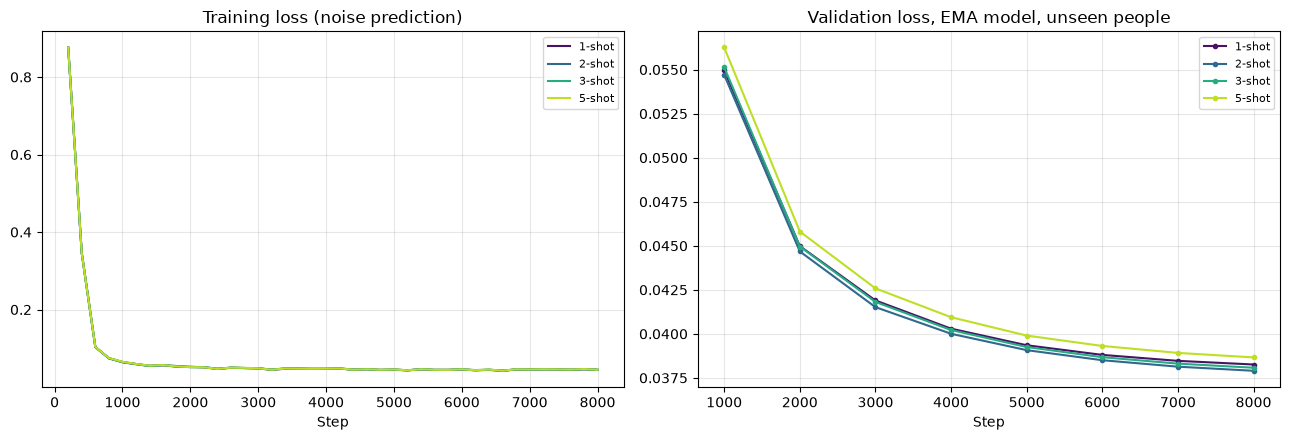

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_training_curves.png


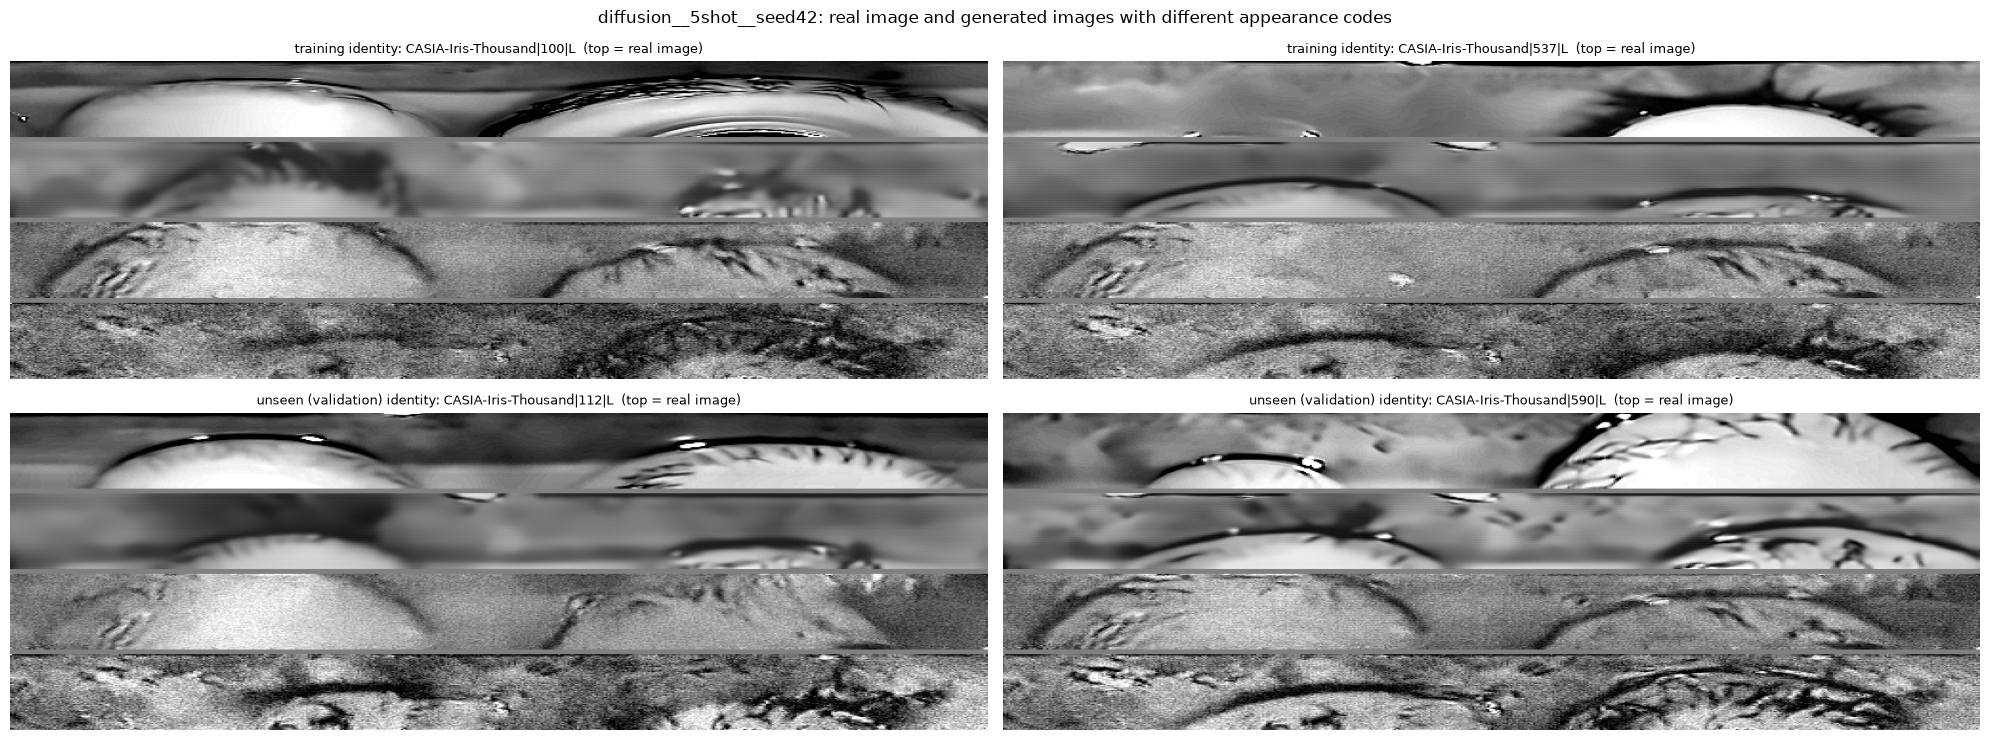

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_samples_diffusion__5shot__seed42.png


In [17]:
# ============================================================
# 15. Training curves and generated samples
# ============================================================

shots_present = sorted(history["shot"].unique())
colors = dict(zip(shots_present, plt.cm.viridis(np.linspace(0.05, 0.9, max(len(shots_present), 1)))))

primary_seed = SEEDS[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for shot in shots_present:
    h = history[(history["shot"] == shot) & (history["seed"] == primary_seed)].sort_values("step")
    validated = h.dropna(subset=["val_loss"])
    axes[0].plot(h["step"], h["loss"], color=colors[shot], label=f"{shot}-shot")
    axes[1].plot(validated["step"], validated["val_loss"], marker="o", markersize=3, color=colors[shot], label=f"{shot}-shot")

axes[0].set_title("Training loss (noise prediction)")
axes[1].set_title("Validation loss, EMA model, unseen people")
for ax in axes:
    ax.set_xlabel("Step")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
curves_path = RESULTS_DIR / "generator_training_curves.png"
plt.savefig(curves_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", curves_path)


def show_generated_samples(run_id, shot, n_identities=2, n_samples=3):
    checkpoint_path = CHECKPOINT_DIR / f"{run_id}.pt"
    if not checkpoint_path.exists():
        print("Checkpoint not found; skipping the sample figure for", run_id)
        return

    model, checkpoint = load_generator(checkpoint_path)
    diffusion = Diffusion(checkpoint["diffusion_steps"], checkpoint["noise_schedule"])
    table = load_latent_assets(shot)["table"]
    pools = get_eval_pool_defs(shot)
    blocks, titles = [], []

    for kind, label in [("train_closed_set_diagnostic", "training identity"), ("selection", "unseen (validation) identity")]:
        pool_name = next((n for n, p in pools.items() if p["spec"]["kind"] == kind), None)
        if pool_name is None:
            continue

        support_df = pools[pool_name]["support_df"]
        classes = sorted(set(support_df["class_id"]))
        classes = classes[::max(1, len(classes) // n_identities)][:n_identities]

        for class_id in classes:
            real = load_image_tensor(support_df[support_df["class_id"] == class_id].iloc[:1])[0].numpy() / 255.0
            bank = checkpoint["app_bank"]
            codes = bank[torch.randint(0, len(bank), (n_samples,))].to(DEVICE)
            identity = torch.tensor(table[class_id], dtype=torch.float32, device=DEVICE).unsqueeze(0).repeat(n_samples, 1)
            images = sample_images(model, diffusion, make_condition(identity, codes),
                                   steps=checkpoint["sample_steps"], guidance=checkpoint["guidance_scale"],
                                   eta=checkpoint["ddim_eta"], gen=make_generator(EVAL_SEED))

            strips = [real] + [image[0].cpu().numpy() for image in images]
            separator = np.full((4, real.shape[1]), 0.5)
            parts = []
            for i, strip in enumerate(strips):
                parts.append(strip)
                if i < len(strips) - 1:
                    parts.append(separator)
            blocks.append(np.vstack(parts))
            titles.append(f"{label}: {class_id}  (top = real image)")

    if not blocks:
        print("No evaluation identities available for the sample figure.")
        return

    fig, axes = plt.subplots(2, 2, figsize=(20, 7.5))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, block, title in zip(axes.flatten(), blocks, titles):
        ax.imshow(block, cmap="gray", vmin=0, vmax=1, aspect="auto")
        ax.set_title(title, fontsize=9)

    plt.suptitle(f"{run_id}: real image and generated images with different appearance codes", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"generator_samples_{run_id}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


if SAVE_CHECKPOINTS:
    largest_shot = max(shots_present)
    show_generated_samples(make_run_id(largest_shot, primary_seed), largest_shot)
else:
    print("SAVE_CHECKPOINTS is False; skipping the sample figure.")

## 16. Sanity checks

A broken generator would silently damage every notebook after it, so the results are checked before they are handed on.

**Stop the notebook if** a planned run is missing, a leakage assertion failed, or a saved generator cannot be loaded and sampled.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- the training loss did not fall, or the validation loss did not improve;
- generated images of training identities are identified at no more than twice chance, or the appearance code is not followed;
- generated images look like copies of the real images, or are far less varied than real ones;
- generated brightness differs strongly from real images.

In [18]:
# ============================================================
# 16. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_ids = {make_run_id(s, sd) for (s, sd) in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the train/evaluation leakage assertions", bool(runs_table["leakage_checks_passed"].all()))

if SAVE_CHECKPOINTS:
    broken = []
    for _, run in runs_table.iterrows():
        try:
            model, checkpoint = load_generator(run["checkpoint"])
            diffusion = Diffusion(checkpoint["diffusion_steps"], checkpoint["noise_schedule"])
            condition = torch.zeros(2, checkpoint["cond_dim"], device=DEVICE)
            sample = sample_images(model, diffusion, condition, steps=2, guidance=1.0, eta=0.0, gen=make_generator(0))
            ok = tuple(sample.shape) == (2, 1, *INPUT_HW) and bool(torch.isfinite(sample).all())
        except Exception as error:
            ok = False
        if not ok:
            broken.append(run["run_id"])
    add_check("every saved generator loads and produces finite images of the right size", not broken, f"{len(broken)} broken")

not_decreasing = runs_table[runs_table["final_loss"] >= runs_table["initial_loss"]]
add_check("training loss decreased in every run", len(not_decreasing) == 0, f"{len(not_decreasing)} run(s) did not improve", critical=False)

no_gain = runs_table[runs_table["best_val_loss"] >= runs_table["first_val_loss"]]
add_check("validation loss improved over the first evaluation", len(no_gain) == 0, f"{len(no_gain)} run(s) did not improve", critical=False)

train_rows = results[results["kind"] == "train_closed_set_diagnostic"]
if len(train_rows):
    weak = train_rows[train_rows["gen_rank1"] <= 2 * train_rows["chance_rank1"]]
    add_check("generated images of training identities are identified at more than twice chance", len(weak) == 0,
              f"{len(weak)} of {len(train_rows)} results", critical=False)

    low_fidelity = train_rows[train_rows["app_fidelity"] <= 0.5]
    add_check("the requested appearance code is followed (fidelity above 0.5)", len(low_fidelity) == 0,
              f"{len(low_fidelity)} of {len(train_rows)} results", critical=False)

    copying = train_rows[train_rows["copy_ratio"] < 0.3]
    add_check("generated images are not copies of the real images (copy ratio above 0.3)", len(copying) == 0,
              f"{len(copying)} of {len(train_rows)} results", critical=False)

    collapsed = train_rows[train_rows["diversity_ratio"] < 0.3]
    add_check("generated images of one person are varied (diversity ratio above 0.3)", len(collapsed) == 0,
              f"{len(collapsed)} of {len(train_rows)} results", critical=False)

    off_brightness = train_rows[(train_rows["gen_mean"] - train_rows["real_mean"]).abs() > 0.1]
    add_check("generated brightness is close to real brightness", len(off_brightness) == 0,
              f"{len(off_brightness)} of {len(train_rows)} results", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "generator_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "generator_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical generator checks failed: {failed_names}"
print("\nGenerator sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the train/evaluation leakage assertions
[PASS] every saved generator loads and produces finite images of the right size  (0 broken)
[PASS] training loss decreased in every run  (0 run(s) did not improve)
[PASS] validation loss improved over the first evaluation  (0 run(s) did not improve)
[PASS] generated images of training identities are identified at more than twice chance  (0 of 4 results)
[PASS] the requested appearance code is followed (fidelity above 0.5)  (0 of 4 results)
[PASS] generated images are not copies of the real images (copy ratio above 0.3)  (0 of 4 results)
[PASS] generated images of one person are varied (diversity ratio above 0.3)  (0 of 4 results)
[PASS] generated brightness is close to real brightness  (0 of 4 results)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator\generator_sanity_checks.csv

Generator sanity checks completed with no critical failures.


## 17. Final outputs

At the end of Notebook 09, the project should contain:

```text
checkpoints/diffusion_generator/
└── diffusion__<K>shot__seed<S>.pt     the generator model (EMA weights, conditioning statistics, appearance bank)

results/diffusion_generator/
├── runs/                              one JSON record per training run
├── generator_results.csv              every diagnostic, every run, every evaluation set
├── generator_summary.csv              averaged over seeds
├── generator_runs.csv, generator_training_history.csv, generator_manifest.csv
├── generator_sanity_checks.csv
└── generator_training_curves.png, generator_samples_<run_id>.png
```

In [19]:
# ============================================================
# 17. Final output listing
# ============================================================

print("Notebook 09 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nRun records: {len(list(RUNS_DIR.glob('*.json')))} | generator checkpoints: {len(list(CHECKPOINT_DIR.glob('*.pt')))}")
print("\nNotebook 09 completed.")

Notebook 09 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\diffusion_generator

Top-level generated files:
- generator_manifest.csv
- generator_results.csv
- generator_runs.csv
- generator_samples_diffusion__5shot__seed42.png
- generator_sanity_checks.csv
- generator_summary.csv
- generator_training_curves.png
- generator_training_history.csv

Run records: 4 | generator checkpoints: 4

Notebook 09 completed.


## 18. What this notebook hands to Notebook 10

```text
Notebook 08                       Notebook 09                          Notebook 10
Identity embeddings,       --->   Conditional diffusion generator --->  Synthetic images for every
appearance codes                  (one per shot)                        training identity
```

### What is in a generator checkpoint

| Key | Content |
|---|---|
| `ema_state`, `unet_args` | The weights and the settings needed to rebuild the U-Net |
| `diffusion_steps`, `noise_schedule` | The noise schedule |
| `app_mean`, `app_std` | Standardisation of appearance codes |
| `app_bank` | Realistic standardised appearance codes of the training images (plain and transformed views): sample from this for varied, plausible appearances |
| `guidance_scale`, `sample_steps`, `ddim_eta` | The sampling settings used in the diagnostics |
| `train_classes`, `latent_run_id`, `shot`, `seed`, `config_hash` | Provenance |

### Generating images in Notebook 10

```python
model, checkpoint = load_generator(CHECKPOINT_DIR / "diffusion__3shot__seed42.pt")
diffusion = Diffusion(checkpoint["diffusion_steps"], checkpoint["noise_schedule"])

# identity_unit: [n, id_dim] identity embeddings of TRAIN classes (Notebook 08, identity_embeddings/<run>.npz)
# app_codes:     [n, app_dim] rows drawn from checkpoint["app_bank"]
condition = make_condition(identity_unit.to(DEVICE), app_codes.to(DEVICE))
images = sample_images(model, diffusion, condition, steps=50, guidance=2.0, eta=0.0)   # [n, 1, 64, 512] in [0, 1]
```

Copy the cells that define `UNet`, `Diffusion`, `sample_images`, `load_generator`, `make_condition`, and the Notebook 08 classes into Notebook 10 unchanged.

### Rules that keep the no-leakage guarantee intact

1. **Generate only for the identities of the training split.** Their identity embeddings come from `train / support` images. Never condition the generator on validation, test, or IITD identities to create training data.
2. **Synthetic images inherit the split of their identity.** They are used for training only; validation and test stay real.
3. Use the generator of the **same shot** as the experiment: the `3shot` generator has seen only 3 real support images per training identity (plus transformed views of them).
4. Report the configuration fingerprint (`CONFIG_HASH`) and the seed with every number.
5. Because the generator is trained on appearance-transformed views, the final comparison (Notebook 16) must include the **traditional-augmentation baseline** of Notebook 07.

### Reading the diagnostics

| What you see | Likely cause | What to try |
|---|---|---|
| Generated images look like noise or blobs | Too few steps, network too small | Raise `TRAIN_STEPS` and/or `UNET_BASE`; check the loss is still falling |
| Identity consistency (`gen_rank1`) near chance | The condition is not followed | Raise `GUIDANCE_SCALE`, train longer, lower `P_UNCOND` |
| Identity ratio high but diversity ratio low | Mode collapse: appearance ignored | Raise `AUGMENT_PROB`, lower `GUIDANCE_SCALE` |
| Copy ratio close to 0 | The model memorises its few training images | Raise `AUGMENT_PROB`, stop earlier, lower `GUIDANCE_SCALE` |
| Appearance fidelity near 0.5 | The appearance code has little effect | Raise `AUGMENT_PROB`; check Notebook 08's swap accuracy |
| Brightness or sharpness differs from real | Under-trained or over-guided sampling | Train longer; lower `GUIDANCE_SCALE` |